## Day 11: Senses – Sound

### Can you hear the city? Mapping railway noise in Vienna.

What does a city sound like? For Day 11 of the #30DayMapChallenge, I explored the invisible geography of railway noise in Vienna, focusing on the area surrounding **Wien Hauptbahnhof (Vienna Central Station)**, located at the center of the map.

The map combines Austria's **2022 strategic railway noise data** with detailed building footprints from the City of Vienna. The colored areas represent different levels of railway noise exposure based on the day-evening-night noise indicator (Lden), while the black building footprints reveal the dense urban structure surrounding the railway network.

What makes this perspective interesting is how far the acoustic footprint of railway infrastructure extends beyond the tracks themselves. Noise follows the railway corridors but also spreads into surrounding neighborhoods, creating an invisible landscape that shapes the everyday experience of the city.

The map was created using **Python, GeoPandas, Matplotlib, and WMS/WFS geodata services**.

#30DayMapChallenge #Day11 #Sound #NoisePollution #Vienna #GIS #Python #Geospatial #SpatialAnalysis

In [20]:
import requests
import geojson
import geopandas as gpd
from matplotlib import pyplot as plt
from io import BytesIO
from PIL import Image

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

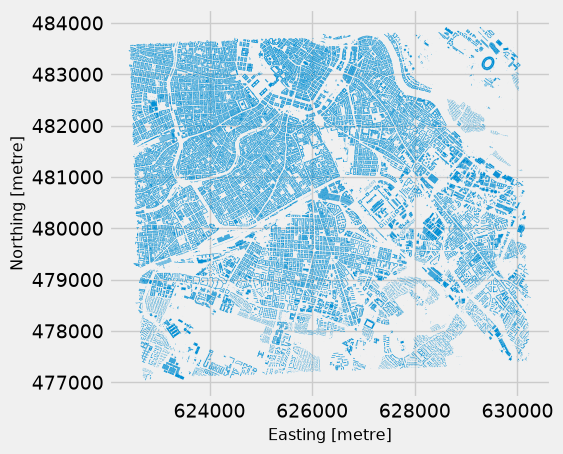

In [4]:
bbox = (622693.3627, 477365.4131, 629994.5810, 483573.6346)

url = "https://data.wien.gv.at/daten/geo"
params = dict(
    service="WFS",
    version="2.0.0",
    request="GetFeature",
    typeNames="ogdwien:FMZKGEBOGD",
    bbox=",".join(map(str, bbox)) + ",EPSG:31287",
    outputFormat="application/json",
    srsName="EPSG:31287"
)
r = requests.get(url, params=params)
geodata = geojson.loads(r.content)
buildings = gpd.GeoDataFrame.from_features(geodata, crs="EPSG:31287")
buildings.plot()


In [17]:
wms_url = "https://inspire.lfrz.gv.at/000804/wms"

params = {
    "SERVICE": "WMS",
    "VERSION": "1.3.0",
    "REQUEST": "GetMap",
    "LAYERS": "2022_SCHIENE_24H_ZONEN_OE",
    "STYLES": "",
    "CRS": "EPSG:31287",
    "BBOX": ",".join(map(str, bbox)),
    "WIDTH": 2000,
    "HEIGHT": 1700,
    "FORMAT": "image/png",
    "TRANSPARENT": "TRUE",
}

params["VERSION"] = "1.1.1"
params.pop("CRS", None)
params["SRS"] = "EPSG:31287"
params["BBOX"] = ",".join(map(str, bbox))

response = requests.get(wms_url, params=params, timeout=60)
response.raise_for_status()

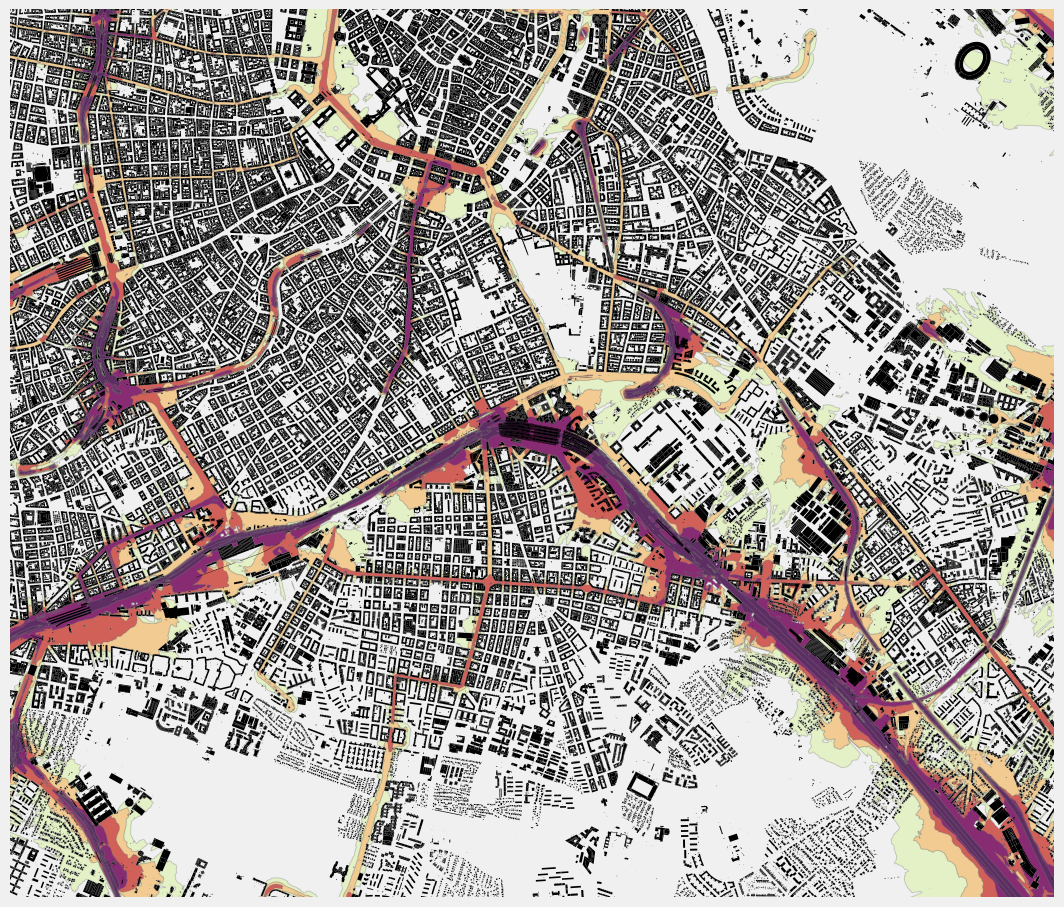

In [21]:
fig, ax = plt.subplots(figsize=(12, 12))

# WMS
ax.imshow(
    img,
    extent=[
        bbox[0],
        bbox[2],
        bbox[1],
        bbox[3]
    ],
    origin="upper",
    zorder=1
)

# Gebäude
buildings.plot(
    ax=ax,
    color="black",
    edgecolor="none",
    zorder=2
)

ax.set_xlim(bbox[0], bbox[2])
ax.set_ylim(bbox[1], bbox[3])
ax.set_aspect("equal")
ax.axis("off")
plt.savefig("maps/map11.png", bbox_inches="tight", dpi=300)
plt.show()